# Gilbert Owen

# 2802432220

# DTSC6008001 – Text Mining

# 4. Topic Modelling

### A. Objective

**Input**: `data/processed/articles_preprocessed.parquet` from Task 2 (6,110 articles, 5 labels). The topic model reads `text_topic`: lowercased tokens with stopwords removed, so the topics are built from content words.

**Task**: find the topics inside each label separately, with one topic model per label.

| Choice | What we use | Why |
|---|---|---|
| Labels | the true channel labels, all 6,110 articles | about 1,100 to 1,300 articles per label; the Task 3 classifiers agree with these labels on 96% of test articles, so predicted labels would give almost the same groups |
| Method | LDA (Latent Dirichlet Allocation) with `gensim` | each article is a mixture of topics and each topic is a list of word weights (S12); `gensim` also scores coherence, which is used to choose the number of topics |
| Number of topics K | tried from 2 to 10 for every label, chosen from the coherence (C_v) plot | no fixed rule gives K, so it is chosen from evidence |

**Rules from the brief**: model each class separately, justify the method and K, and show keywords, topic names, representative articles and visualizations.

**Target**: Find the main topics inside each of the 5 labels, choose the number of topics for each label from coherence, name every topic, and save each article's topic for the topic-aware summaries in Task 5.

### B. Import Libraries and Environment Check

The same `deep-learning` environment as Task 3. `gensim` 4.3.3 was installed for this task (it is in `requirements.txt`); no GPU is needed, LDA runs on the CPU.

In [1]:
import random
from pathlib import Path

import gensim
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from gensim.corpora import Dictionary
from gensim.models import CoherenceModel, LdaModel

print("gensim: {}".format(gensim.__version__))
print("pandas: {}".format(pd.__version__))

gensim: 4.3.3
pandas: 2.3.3


### C. Configuration

All settings live in this one cell. `SEED` is the same as in Tasks 2 and 3; LDA starts from random topic assignments, so the seed makes every run give the same topics.

In [6]:
SEED = 42
K_RANGE = range(2, 11)   # numbers of topics tried for every label
NO_BELOW = 5     # drop words found in fewer than 5 articles of the label
NO_ABOVE = 0.5   # drop words found in more than half of the label's articles
PASSES = 10      # times LDA reads all articles of a label while training
CHOSEN_K = {"business": 8, "entertainment": 8, "health": 4, "sports": 6, "technology": 6}   # chosen from the coherence plots in F
TOP_WORDS = 10   # keywords shown per topic
TOP_DOCS = 3     # representative articles shown per topic

PROC_DIR = Path("../data/processed")
PREPROCESSED_PARQUET = PROC_DIR / "articles_preprocessed.parquet"

random.seed(SEED)
np.random.seed(SEED)

print("articles_preprocessed.parquet found: {}".format(PREPROCESSED_PARQUET.exists()))

articles_preprocessed.parquet found: True


### D. Load the Preprocessed Articles

Read the file Task 2 saved and split `text_topic` into tokens. All three splits are used together, because topic modelling has no train/test step: it describes the articles, it does not predict them. `title` is kept to show representative articles later. Expected: 6,110 articles.

In [3]:
df = pd.read_parquet(PREPROCESSED_PARQUET, columns=["label", "title", "text_topic"])
df["tokens"] = df["text_topic"].str.split()
df["n_tokens"] = df["tokens"].str.len()

LABELS = sorted(df["label"].unique())
print("Articles: {} | labels: {}".format(len(df), LABELS))
df.groupby("label")["n_tokens"].describe()[["count", "min", "50%", "max"]].astype(int)

Articles: 6110 | labels: ['business', 'entertainment', 'health', 'sports', 'technology']


,count,min,50%,max
label,,,,
business,1221,67,204,945
entertainment,1087,6,150,449
health,1279,11,207,905
sports,1279,14,148,1077
technology,1244,47,239,926


### E. Dictionary and Corpus per Label

Each label gets its own dictionary (word to id) and corpus (each article as word-id counts), because each label has its own topic model. Rare words (in fewer than `NO_BELOW` = 5 articles) are mostly typos and one-off names, and very common words (in more than `NO_ABOVE` = 50% of the label's articles) appear in every topic, so both are removed before LDA.

In [4]:
dictionaries, corpora, texts = {}, {}, {}
rows = []
for label in LABELS:
    docs = df.loc[df["label"] == label, "tokens"].tolist()
    dictionary = Dictionary(docs)
    before = len(dictionary)
    dictionary.filter_extremes(no_below=NO_BELOW, no_above=NO_ABOVE)
    dictionaries[label] = dictionary
    corpora[label] = [dictionary.doc2bow(doc) for doc in docs]
    texts[label] = docs
    rows.append({"label": label, "articles": len(docs), "vocab_before": before, "vocab_after": len(dictionary),
                 "empty_articles": sum(len(bow) == 0 for bow in corpora[label])})

pd.DataFrame(rows).set_index("label")

,articles,vocab_before,vocab_after,empty_articles
label,,,,
business,1221,21810,4854,0
entertainment,1087,15422,3625,0
health,1279,21225,5568,0
sports,1279,18103,4497,0
technology,1244,25579,6372,0


**What the numbers show**: The extremes filter (NO_BELOW = 5, NO_ABOVE = 50%) reduced the vocabulary by roughly 75% in every label, for example entertainment from 15,422 to 3,625 words and health from 21,225 to 5,568. Removing rare words such as typos and one-off names, and very common words that appear in most articles, should remove noise, so the model runs faster and the topics are cleaner.

### F. Choosing K: Coherence Sweep

For every label, LDA is trained once for each K from 2 to 10, and each model is scored with C_v coherence (S12): for the top words of each topic, it measures how often they appear together in the same articles, so a higher C_v means topics whose words belong together. The seed is fixed, so the only difference between the models of one label is K. Every model is kept, so Section G can use the chosen K without training again. This cell takes about 15 minutes.

business      done
entertainment done
health        done
sports        done
technology    done


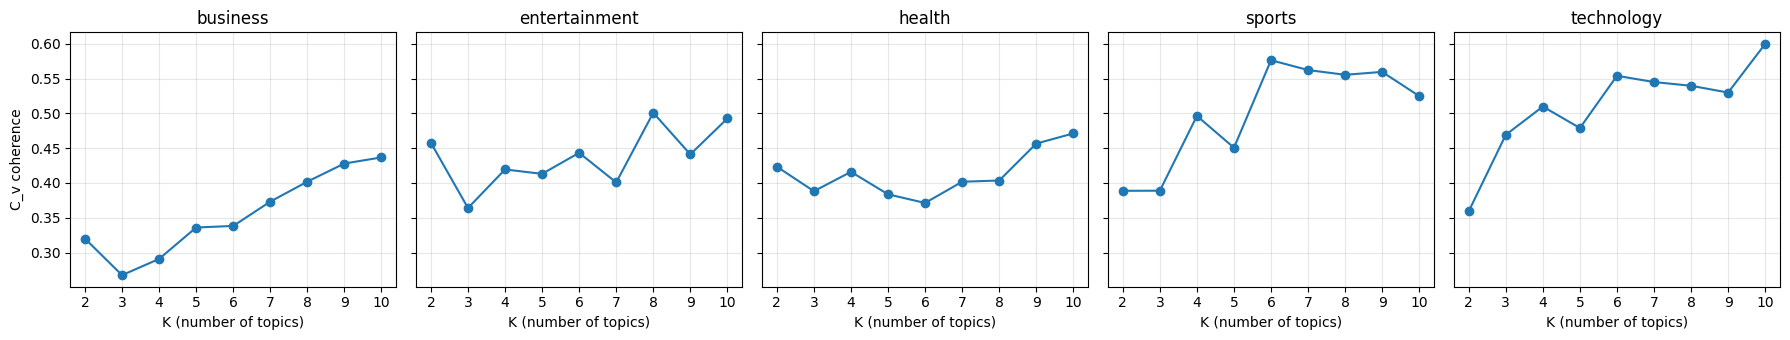

label,business,entertainment,health,sports,technology
k,,,,,
2,0.320,0.458,0.423,0.389,0.359
3,0.267,0.364,0.388,0.389,0.469
4,0.291,0.419,0.416,0.496,0.510
5,0.336,0.413,0.384,0.451,0.479
6,0.338,0.443,0.371,0.576,0.554
7,0.373,0.401,0.402,0.562,0.545
8,0.402,0.501,0.403,0.555,0.540
9,0.428,0.441,0.457,0.560,0.530
10,0.437,0.493,0.471,0.525,0.600


In [5]:
models, scores = {}, []
for label in LABELS:
    models[label] = {}
    for k in K_RANGE:
        lda = LdaModel(corpora[label], id2word=dictionaries[label], num_topics=k, passes=PASSES, random_state=SEED)
        c_v = CoherenceModel(model=lda, texts=texts[label], dictionary=dictionaries[label], coherence="c_v", processes=1).get_coherence()
        models[label][k] = lda
        scores.append({"label": label, "k": k, "c_v": c_v})
    print("{:13s} done".format(label))

coherence = pd.DataFrame(scores).pivot(index="k", columns="label", values="c_v")

fig, axes = plt.subplots(1, len(LABELS), figsize=(18, 3.5), sharey=True)
for ax, label in zip(axes, LABELS):
    ax.plot(coherence.index, coherence[label], marker="o")
    ax.set_title(label)
    ax.set_xlabel("K (number of topics)")
    ax.set_xticks(list(K_RANGE))
    ax.grid(alpha=0.3)
axes[0].set_ylabel("C_v coherence")
plt.tight_layout()
plt.show()

coherence.round(3)

**What the coherence shows**: Sports has the clearest answer: C_v peaks at K = 6 (0.576) and stays flat or drops a little after it. Business keeps rising up to K = 10 (0.437, the largest K tried), but the gain flattens at the end: +0.026 from K = 8 to 9 and only +0.009 from 9 to 10. Entertainment has an unstable curve, with its peak at K = 8 (0.501). Health dips in the middle (lowest at K = 6, 0.371) and rises again to 0.471 at K = 10. Technology has a local peak at K = 6 (0.554) and its highest point at K = 10 (0.600), but 10 topics are not worth the extra complexity, so we choose K = 6 for technology. The curves zigzag and every K was trained with a single seed, so differences of about 0.03 may be noise rather than real differences, and small gaps are treated as ties. K also matters for Task 5: every topic must appear in the class summary, so a larger K means a longer summary and more topics to name. The chosen K per label: business 8, entertainment 8, health 4, sports 6, technology 6.

### G. Final Topics: Keywords and Representative Articles

For each label, the model with the chosen K from F is reused (no new training). LDA gives every article a share of each topic; the topic with the largest share is the article's **dominant topic**. Each topic is shown with:

- **keywords**: its `TOP_WORDS` most likely words, in order of weight
- **articles**: how many articles have it as their dominant topic
- **representative articles**: the titles of the `TOP_DOCS` articles with the largest share of that topic

In [7]:
topic_tables = {}
for label in LABELS:
    lda = models[label][CHOSEN_K[label]]
    titles = df.loc[df["label"] == label, "title"].tolist()

    theta = np.zeros((len(corpora[label]), lda.num_topics))   # topic share of every article
    for i, bow in enumerate(corpora[label]):
        for t, share in lda.get_document_topics(bow, minimum_probability=0):
            theta[i, t] = share
    dominant = theta.argmax(axis=1)

    rows = []
    for t in range(lda.num_topics):
        best = np.argsort(theta[:, t])[::-1][:TOP_DOCS]
        rows.append({
            "topic": t + 1,
            "keywords": ", ".join(word for word, _ in lda.show_topic(t, TOP_WORDS)),
            "articles": int((dominant == t).sum()),
            "representative articles": " | ".join(titles[i] for i in best),
        })
    topic_tables[label] = pd.DataFrame(rows).set_index("topic")

with pd.option_context("display.max_colwidth", None):
    for label in LABELS:
        print("{} (K = {})".format(label, CHOSEN_K[label]))
        display(topic_tables[label])

business (K = 8)


,keywords,articles,representative articles
topic,,,
1,"pemerintah, ekonomi, program, prabowo, rp, masyarakat, triliun, umkm, usaha, anggaran",219,"Cangcomak Tumbuh Bersama BRI: Dari Camilan Lebaran Jadi Bisnis Menjanjikan | Cerita Vivi Cuan Jutaan Rupiah dari Jualan Bumbu Masakan Khas Aceh | Desil 1-10 Menentukan Nasib Bansos dan Pertalite, Cek Posisi Kamu di Sini"
2,"industri, perusahaan, nasional, mendukung, masyarakat, memperkuat, pertumbuhan, pt, pengembangan, pembangunan",164,"Perkuat Ekonomi Nasional, Waskita Karya Bangun 29 Bendungan dalam 1 Dekade | Proyek Pipa Gas Dusem Segmen 2 Garapan Brantas Abipraya Capai 32% | Mitrapak Perkuat Penerapan Standar Global ESG di Industri Personal Care"
3,"pt, pajak, tbk, jakarta, kereta, layanan, tol, jalan, rp, stasiun",133,"Kapal Perintis NTT Beroperasi Lagi Usai Pelni & ASDP Diguyur Rp 209 M | Merchant Indonesia Bisa Terima Pembayaran dari Luar Negeri, Ini Caranya | Kemenhub Jamin Kapal Perintis di NTT Tak Dihentikan"
4,"keuangan, pemerintah, purbaya, negara, kebijakan, bank, ekonomi, perusahaan, presiden, ojk",243,"Penggunaan Dana SAL Kini Dibagi Dua Skema, Ini Bedanya | KSP & Bahlil Buka Suara soal Ekspor 'Harta Karun' RI | Pemerintah Lindungi Investor yang Beli Obligasi Danantara, Purbaya Buka Suara"
5,"masyarakat, listrik, wilayah, beras, pln, kebutuhan, energi, kementerian, pemerintah, kondisi",152,"BPH Migas-Pertamina Patra Niaga Percepat Normalisasi Distribusi BBM di Sumut | ESDM Buka Suara soal Penyebab BBM Langka di Medan | Bea Cukai Sita 43 Kontainer Baju Bekas Impor Ilegal Rp 37,5 M di Tanjung Priok"
6,"minyak, as, juta, us, harga, bri, bni, dolar, rp, 3",154,"Harga Minyak Mentah RI Turun Jadi US$ 106,56 per Barel | Transfer Uang ke LN Kian Praktis Pakai BRImo, Ada Cashback hingga Rp 50.000 | Harga Minyak Nabati Dunia Meroket, Ini Biang Keroknya"
7,"saham, pasar, indeks, ihsg, level, perdagangan, menguat, melemah, msci, investor",81,"Apa Beda Emerging Market dan Frontier Market MSCI? | S&P Buka Opsi Turunkan Status Pasar Modal RI, BEI Buka Suara | MSCI Ingatkan RI Bisa Turun ke Frontier Market, Ini Jawaban Pemerintah"
8,"rp, harga, emas, gram, triliun, pertamax, antam, miliar, turun, liter",75,"Pertamax Rp 15.950/Liter, Cek Daftar Harga Terbaru BBM di SPBU Pertamina | Harga BBM Pertamina Mulai 1 Juni, Ada yang Naik | Cek Harga BBM di Semua SPBU Berlaku Juni"


entertainment (K = 8)


,keywords,articles,representative articles
topic,,,
1,"indonesia, film, musik, lagu, dunia, gak, cinta, ratu, karya, salah",159,Kata Vino G Bastian Soal Aktor Down Syndrome di Film Tanah Runtuh Jadi Sorotan | Lomba 17-an ala Fajar Sadboy | Teaser Poster Bapakmu Kiper Tampilkan Aksi Fedi Nuril Jaga Gawang
2,"anak, ya, nggak, aldi, mengaku, gitu, orang, taher, udah, memiliki",132,"Selebritas Ikut Nangis, Lihat Anak di Bali Histeris Ayah Tewas Dihakimi Massa | Akun Instagram Berubah Jadi Happy Boy, Ini Penjelasan Fajar | Selvi Kitty Bersyukur Hamil Alami: Padahal Niat Program Bayi Tabung"
3,"hanania, umrah, kerja, ya, travel, polda, jaya, dugaan, metro, pemeriksaan",91,"Keanu Angelo Dicecar 25 Pertanyaan di Pemeriksaan Kasus Hanania Travel | Pengakuan Istri Alami KDRT Saat Minta Nafkah Bulanan, Evan Marvino Bersuara | Keanu Diperiksa Terkait Hanania Travel, Tegaskan Gak Terima Uang Endorse"
4,"ya, gitu, nggak, rumah, mengaku, kondisi, sang, jakarta, sih, gak",249,Istri Ungkap Detik-detik Temon Meninggal usai Serangan Jantung | Kenangan Malam Terakhir Istri dengan Temon | Jaga Mental Jadi Kunci Aida Saskia Kuat Hadapi Kanker Stadium 3
5,"lagu, anak, ya, orang, nggak, penyanyi, teddy, rizky, mengaku, rossa",155,Pengacara Teddy soal Aset Warisan Eks Istri Sule Usai Banding Dikabulkan | Cek Fakta Isu Cita Rahayu Gugat Cerai Didi Mahardika | Didi Mahardika Tegaskan Hoax Cita Rahayu Gugat Cerai
6,"ruben, onsu, minola, sarwendah, rumah, sebayang, ya, anak, anak-anak, nggak",101,Kata Pihak Sarwendah soal Jumlah Utang Ruben Onsu: Ada Status Kredit Macet | 4 Penegasan Pihak El Rumi Dikaitkan dengan Inisial EJR | Ruben Onsu Rela Utang Rp10 M demi Turuti Keinginan Sarwendah Renovasi Rumah
7,"hukum, kuasa, proses, ya, jakarta, pengadilan, laporan, perkara, terkait, gugatan",136,"Sidang Adik Keisya Levronka Jatuh dari Lantai 6, Gugat Kampus Rp1 M Lebih | Reza Gladys Adukan Rekaman Suara Diduga Nikita Mirzani soal Dugaan Suap ke MA | Reaksi Reza Gladys Usai Gugatan PMH Rp 244 M Nikita Mirzani Ditolak"
8,"richard, lee, raffi, tangerang, doktif, hukum, dokter, ahmad, persidangan, negeri",64,"Hakim Tolak Eksepsi Richard Lee | Eksepsi Richard Lee: Klaim Sedang di Singapura-Dakwaan Salah Sasaran | Sidang Richard Lee akan Digelar di PN Tangerang, Ditangani 7 JPU"


health (K = 4)


,keywords,articles,representative articles
topic,,,
1,"masyarakat, obat, program, indonesia, produk, mbg, bpom, pemerintah, bgn, gizi",275,"Pemborosan MBG Rp 1 T per Bulan, Insentif 6 Juta Sehari Bakal Distop? BGN Bilang Gini | Gebrakan Baru BGN! Insentif Tak Lagi Rp 6 Juta-Pegawainya Tak Boleh Jadi 'Owner' SPPG | BPOM Siap Kawal Koperasi Merah Putih Lewat Perizinan hingga Pengawasan Produk"
2,"susu, anak, orang, latihan, 6, 3, produk, 2, 5, memiliki",232,"Ragam Keseruan Aktivitas di Frisian Flag, Temani Langkahmu, Kini dan Nanti | Pola Asuh Tanpa Tuntutan Sempurna, Cara Bunda Dukung Potensi Unik Anak | Frisian Flag Edukasi Kebaikan Susu-Nutrisi Anak untuk Kini dan Nanti"
3,"dokter, pasien, dr, sakit, kanker, rumah, medis, indonesia, mengalami, pemeriksaan",357,"Tak Perlu ke Luar Negeri, Ini Dokter Saraf Kejepit Terbaik di Indonesia | Ramai-ramai Klarifikasi usai Gaduh Komentar Nirempati Dokter-Nakes soal Pasien BPJS | Nasib Dokter-Nakes Usai Viral Hina Pasien BPJS, Praktik Disetop hingga Terancam Sanksi"
4,"darah, tubuh, makan, makanan, ginjal, dr, penyakit, risiko, orang, membantu",415,"Pangkas 11 Kg dalam 2 Bulan! Pria Jepang Ini Bocorkan Trik Diet Mentimun yang Super Ampuh | Kelompok Ini Paling Butuh Asupan Vitamin B Kompleks | Mudah Dibuat di Rumah, 7 Minuman Ini Bisa Bantu Turunkan Berat Badan"


sports (K = 6)


,keywords,articles,representative articles
topic,,,
1,"motogp, posisi, marquez, balapan, 1, pebalap, poin, 3, indonesia, rider",198,"Piala AFF U-19: Indonesia Sedang Perkasa di Laga Pamungkas Fase Grup | MotoGP Inggris 2026: Raul Fernandez Juara dengan Balapan Sempurna | Tebak Juara MotoGP Jerman di Bold Riders Podium Picks, Menangkan Hadiah HP!"
2,"madrid, musim, pemain, liverpool, real, klub, salah, transfer, arsenal, juta",145,Bernardo Silva Diyakini Mudah Adaptasi dengan Para Bintang Real Madrid | Mohamed Salah Debut di Liga Turki Malam Ini | Bernardo Silva Tak Masalah Mainkan Banyak Peran di Madrid
3,"pemain, musim, dunia, piala, klub, chelsea, city, tim, liga, persija",334,"City Akui Dekati Maresca Sejak Masih di Chelsea, Setuju Bayar Kompensasi | Rogers Dibeli, Lagi-lagi Chelsea Kepincut Eks Man City | STY Pastikan Persija Rekrut 1 Pemain Asing Lagi"
4,"indonesia, 21, open, putri, juara, ganda, gim, turnamen, putra, 6",193,"Doubles Special Championship 2026 Selesai, Ini Hasilnya | Pegolf Thailand Berjaya, Wakil Indonesia Impresif di MCGJWC 2026 | Australian Open 2026: Indonesia Loloskan 3 Wakil ke Final"
5,"gol, laga, menit, 1, pemain, 2, 0, united, musim, gawang",220,"Newcastle Vs Liverpool Selesai 2-2: Gol Penalti Szoboszlai Selamatkan The Reds | Inter Miami vs Montreal: Messi Quat-trick, Tuan Rumah Pesta Gol 7-1 | Elche Vs Barcelona: Juara Bertahan Pesta Gol 5-0"
6,"indonesia, olahraga, atlet, tim, jakarta, dunia, nasional, games, internasional, asian",189,"FPTI DKI Jakarta Gelar Rakerprov, Bahas Sistem Pembinaan | KOI Dorong Transformasi Integrasi Ekosistem Olahraga | Indonesia Tuan Rumah Kejuaraan Dunia Sepak Takraw 2027"


technology (K = 6)


,keywords,articles,representative articles
topic,,,
1,"galaxy, perangkat, pengguna, 8, samsung, layar, fold, z, fitur, kamera",163,"Sebelum Beli HP Mid-Range, Ini 7 Hal yang Wajib Diperhatikan | Fitur Unggulan Samsung Galaxy Z Fold8 Ultra yang Bikin Kerja Makin Praktis | Samsung Galaxy Z Fold8 vs Z Fold8 Ultra: Mana yang Layak Dibeli?"
2,"game, apple, pengguna, fitur, harga, iphone, aplikasi, perangkat, 6, whatsapp",244,"Menanti Kejutan Apple di WWDC Terakhir Bersama Tim Cook | Tak Perlu Scan, Ini Cara Gunakan QRIS Tap Biar Transaksi Praktis | 75% Game PS3 Kini Bisa Dimainkan di PC"
3,"g, 5, jaringan, wilayah, layanan, operator, laut, internet, kondisi, memiliki",202,Apakah 5G Memerlukan Paket Khusus? Ini yang Perlu Diketahui | Jejak Kaki Dinosaurus 150 Juta Tahun Ungkap Dugaan Berjalan Pincang | Sistem Peringatan Dini Kirim 600.000 Pesan ke HP Warga Nepal
4,"ai, perusahaan, teknologi, china, sistem, memiliki, bumi, usd, matahari, data",254,"3 Sosok Genius di Balik Ledakan AI China, Silicon Valley Ketar-ketir | Cetak Rekor, Kereta Maglev China Tembus 800 Km/Jam dalam 5,3 Detik! | Deretan Bos AI yang Mendadak Kaya Raya di Usia 20-an"
5,"digital, indonesia, ai, teknologi, layanan, pemerintah, data, masyarakat, infrastruktur, industri",174,"Regulasi Baru Ancam Kepastian Hukum Kurir Online | Kabel Laut Nongsa-Changi Diharap Mampu Perkuat Gerbang Digital Indonesia | Spin-Off Rampung, InfraNexia Kelola 112 Ribu Km Fiber Optik"
6,"dunia, tim, piala, indonesia, pemain, gol, pertandingan, media, sosial, 2",207,"Dembele Hat-trick Antar Prancis Permalukan Norwegia, Haaland Disorot | Argentina Bangkit dari Neraka! Hajar Mesir, Netizen Teriak 'Anak FIFA' | Haaland vs Gabriel! Netizen Tak Sabar Norwegia Lawan Brasil"


**What the topics show**: The keywords of most topics match their label, for example technology has galaxy, ai, teknologi, digital and apple. This is partly by design: every label has its own model, so its topics can only come from that label's articles. However, some topics contain keywords that do not seem to belong to their label. Technology topic 6 has dunia, tim, piala, pemain, gol and pertandingan together with media and sosial, and its representative articles are football stories about netizen reactions. These articles are in Detik's technology channel, so this is not a misclassification by LDA. *[your explanation of why they might be there]* Technology is not the only label with noisy topics. In entertainment, topics 2, 4 and 5 are led by informal words such as ya, nggak, gitu and udah, which are not in the NLTK stopword list. Numbers appear as keywords in health topic 2, sports topics 1 and 4, and business topic 6. The representative articles of health topic 2 are Frisian Flag advertorials. We keep these words instead of adding more stopwords, because removing them would mean training every model again and choosing K again, so we treat them as a known limit of the topics.

### H. Visualizations

Two charts per the brief: how large each topic is (articles whose dominant topic it is), and the top keywords of every topic with their weights. A longer bar in the keyword chart means LDA gives that word a higher probability inside the topic.

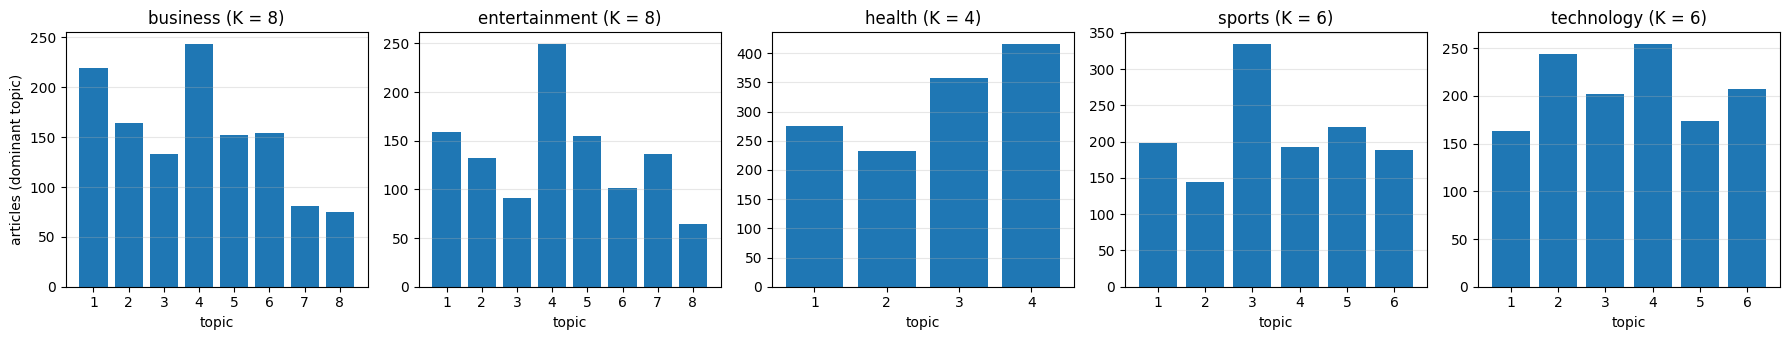

In [10]:
fig, axes = plt.subplots(1, len(LABELS), figsize=(18, 3.5))
for ax, label in zip(axes, LABELS):
    sizes = topic_tables[label]["articles"]
    ax.bar(sizes.index.astype(str), sizes.values)
    ax.set_title("{} (K = {})".format(label, CHOSEN_K[label]))
    ax.set_xlabel("topic")
    ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("articles (dominant topic)")
plt.tight_layout()
plt.show()

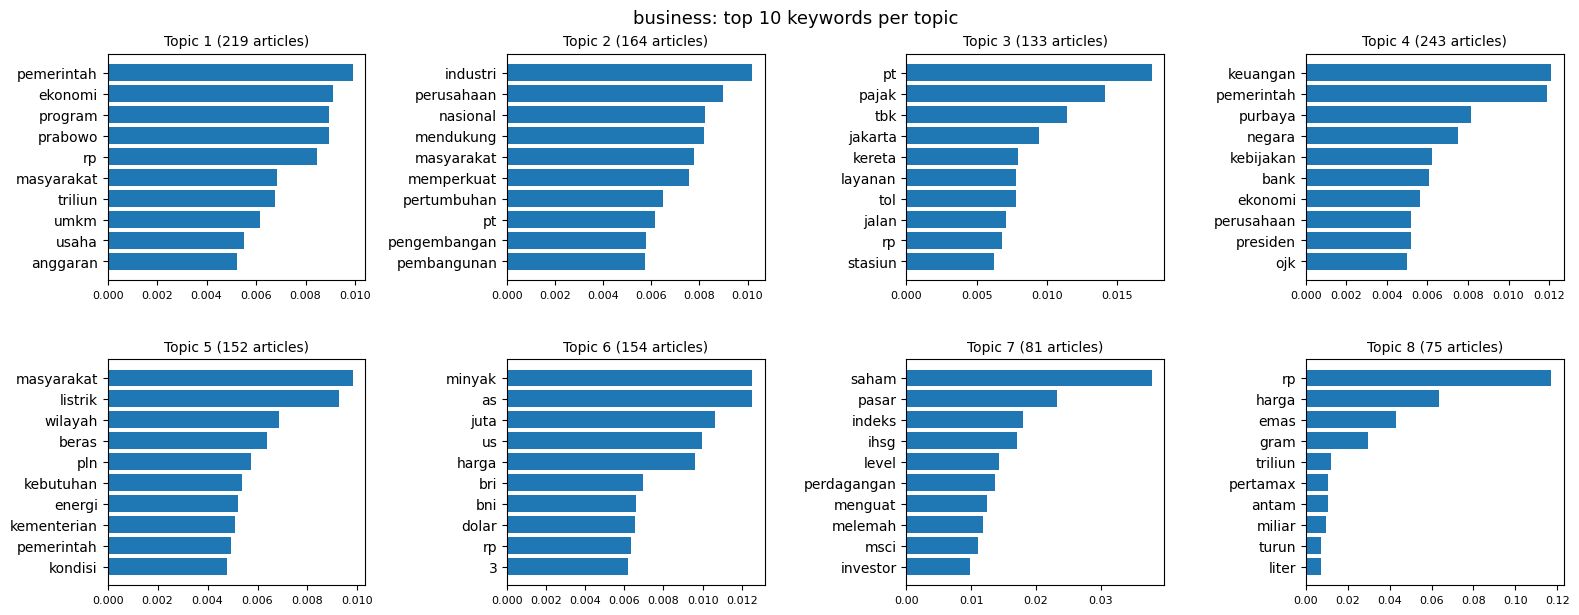

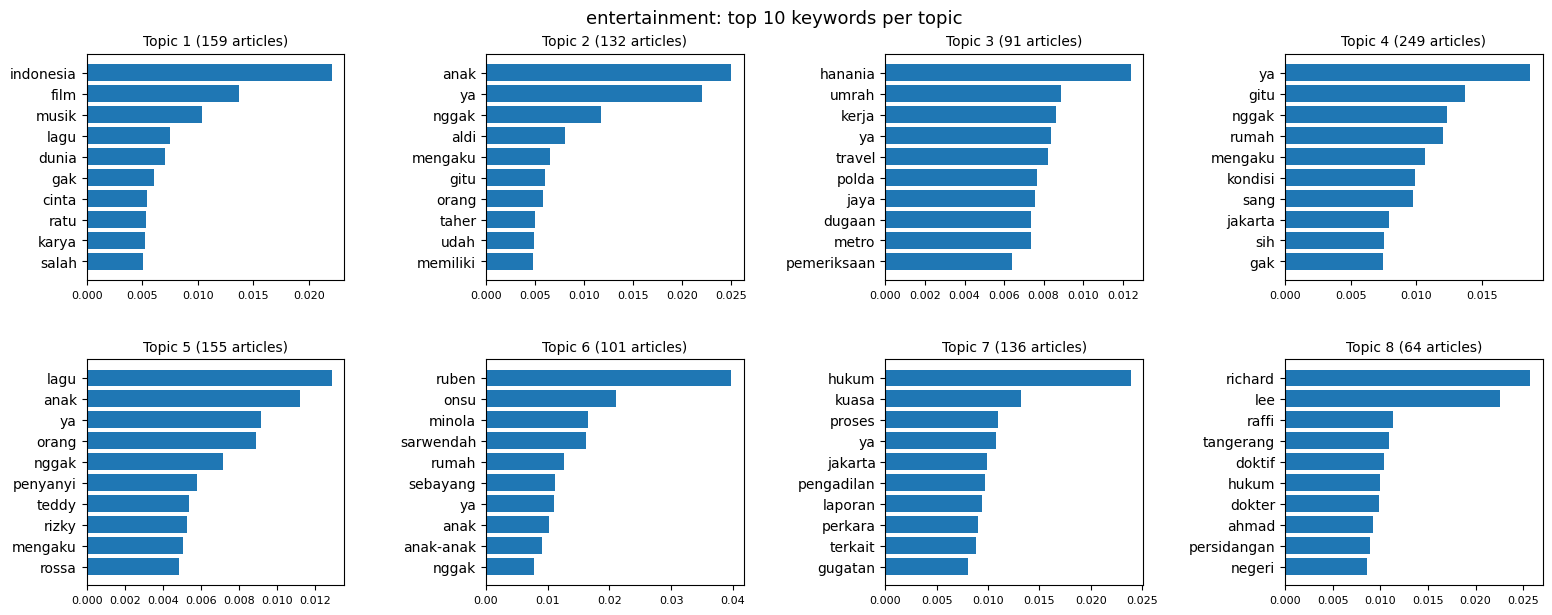

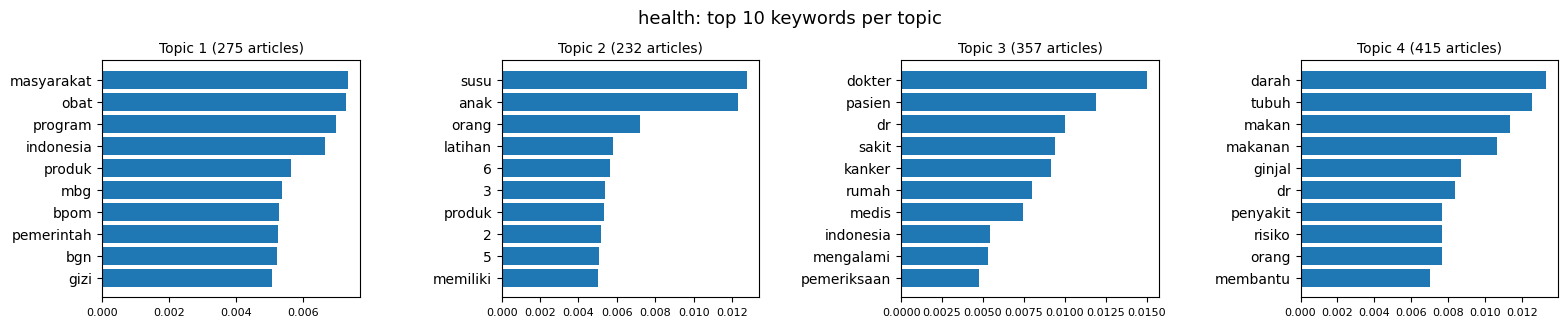

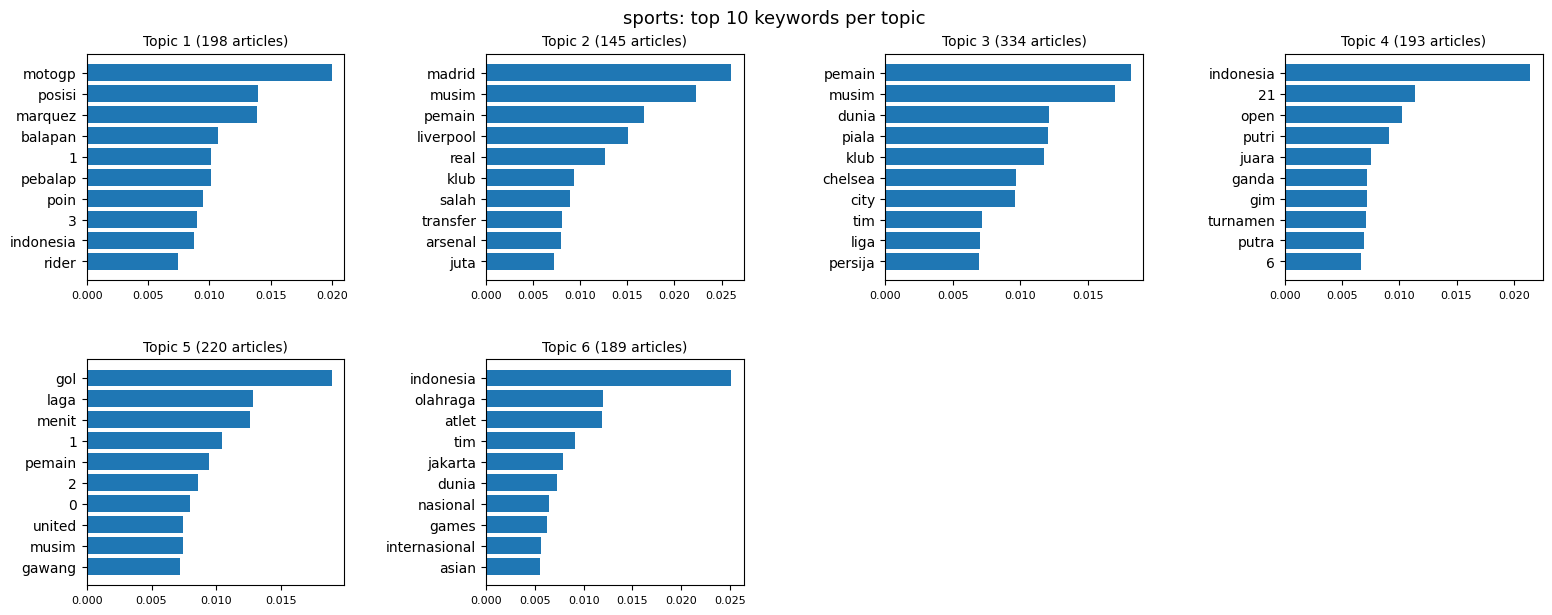

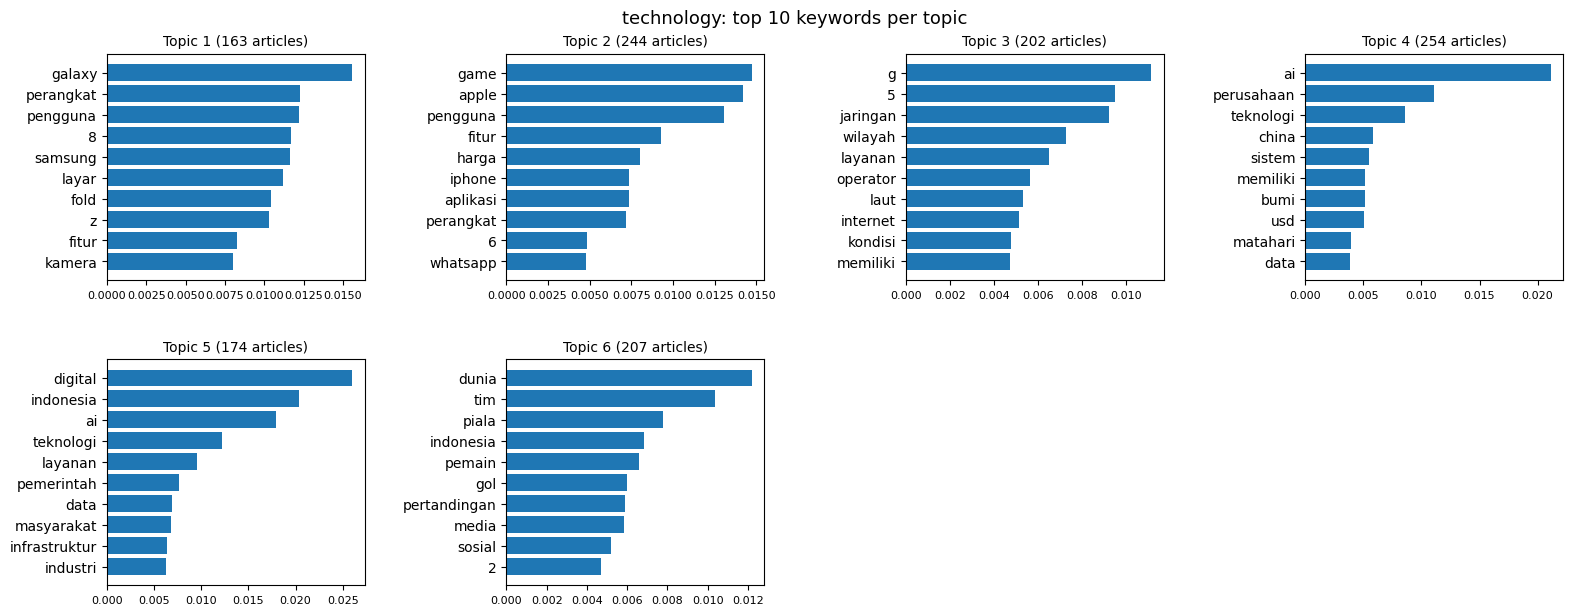

In [11]:
for label in LABELS:
    lda = models[label][CHOSEN_K[label]]
    n_cols = 4
    n_rows = int(np.ceil(lda.num_topics / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 3.2 * n_rows), squeeze=False)
    for t, ax in enumerate(axes.flat):
        if t >= lda.num_topics:
            ax.axis("off")
            continue
        words, weights = zip(*lda.show_topic(t, TOP_WORDS))
        ax.barh(words[::-1], weights[::-1])
        ax.set_title("Topic {} ({} articles)".format(t + 1, topic_tables[label].loc[t + 1, "articles"]), fontsize=10)
        ax.tick_params(axis="x", labelsize=8)
    fig.suptitle("{}: top {} keywords per topic".format(label, TOP_WORDS), fontsize=13)
    fig.subplots_adjust(left=0.07, right=0.98, top=0.82 if n_rows == 1 else 0.91, bottom=0.08, wspace=0.55, hspace=0.35)   # fixed spacing instead of tight_layout, which hung here
    plt.show()

**What the charts show**: The topic-size chart shows that no topic is empty or very small: the smallest are entertainment topic 8 (64 articles, 6% of the label) and business topics 7 and 8 (81 and 75 articles), while the largest are health topic 4 (415 articles, 32% of health) and sports topic 3 (334). Health, with only 4 topics, has the largest topics. The keyword charts show that in most topics the top word is only slightly heavier than the second (1.0 to 1.3 times), so these topics are defined by a group of words rather than by one word. A few topics are led by a single word: business topic 8 by rp (weight 0.117, the heaviest word in any topic and 1.8 times the next word, harga), entertainment topic 6 by ruben (1.9 times onsu), entertainment topic 7 by hukum (1.8 times kuasa), technology topic 4 by ai (1.9 times perusahaan), and sports topics 4 and 6 by indonesia (about 2 times the next word). Health has the flattest topics: its top word is at most 1.3 times the second.

### I. Topic Names

Each topic gets a short name, chosen by reading its keywords (G and H) and its representative articles (G). The names are written into `TOPIC_NAMES` below, one list per label in topic order (topic 1 first), so the table and Task 5 use the same names.

In [15]:
TOPIC_NAMES = {
    "business": ["ekonomi", "industri", "pt", "keuangan", "masyarakat", "minyak", "saham", "rp"],
    "entertainment": ["film", "anak", "hanania", "rumah", "lagu", "ruben", "hukum", "richard"],
    "health": ["obat", "susu", "dokter", "darah"],
    "sports": ["motogp", "madrid", "pemain", "indonesia", "gol", "olahraga"],   # topic 4: your name
    "technology": ["galaxy", "game", "jaringan", "ai", "digital", "dunia"],   # topic 6: your name
}

for label in LABELS:
    assert len(TOPIC_NAMES[label]) == CHOSEN_K[label], "{} needs {} names".format(label, CHOSEN_K[label])

named = pd.concat({label: topic_tables[label].assign(name=TOPIC_NAMES[label])[["name", "keywords", "articles"]] for label in LABELS}, names=["label", "topic"])
with pd.option_context("display.max_colwidth", None):
    display(named)

name  \
label         topic               
business      1         ekonomi   
              2        industri   
              3              pt   
              4        keuangan   
              5      masyarakat   
              6          minyak   
              7           saham   
              8              rp   
entertainment 1            film   
              2            anak   
              3         hanania   
              4           rumah   
              5            lagu   
              6           ruben   
              7           hukum   
              8         richard   
health        1            obat   
              2            susu   
              3          dokter   
              4           darah   
sports        1          motogp   
              2          madrid   
              3          pemain   
              4       indonesia   
              5             gol   
              6        olahraga   
technology    1          galaxy   
              2            game   
              3        jaringan   
              4              ai   
              5         digital   
              6           dunia   

                                                                                                                          keywords  \
label         topic                                                                                                                  
business      1                              pemerintah, ekonomi, program, prabowo, rp, masyarakat, triliun, umkm, usaha, anggaran   
              2      industri, perusahaan, nasional, mendukung, masyarakat, memperkuat, pertumbuhan, pt, pengembangan, pembangunan   
              3                                                  pt, pajak, tbk, jakarta, kereta, layanan, tol, jalan, rp, stasiun   
              4                         keuangan, pemerintah, purbaya, negara, kebijakan, bank, ekonomi, perusahaan, presiden, ojk   
              5                      masyarakat, listrik, wilayah, beras, pln, kebutuhan, energi, kementerian, pemerintah, kondisi   
              6                                                                minyak, as, juta, us, harga, bri, bni, dolar, rp, 3   
              7                                   saham, pasar, indeks, ihsg, level, perdagangan, menguat, melemah, msci, investor   
              8                                              rp, harga, emas, gram, triliun, pertamax, antam, miliar, turun, liter   
entertainment 1                                                indonesia, film, musik, lagu, dunia, gak, cinta, ratu, karya, salah   
              2                                                 anak, ya, nggak, aldi, mengaku, gitu, orang, taher, udah, memiliki   
              3                                         hanania, umrah, kerja, ya, travel, polda, jaya, dugaan, metro, pemeriksaan   
              4                                                  ya, gitu, nggak, rumah, mengaku, kondisi, sang, jakarta, sih, gak   
              5                                               lagu, anak, ya, orang, nggak, penyanyi, teddy, rizky, mengaku, rossa   
              6                                        ruben, onsu, minola, sarwendah, rumah, sebayang, ya, anak, anak-anak, nggak   
              7                                  hukum, kuasa, proses, ya, jakarta, pengadilan, laporan, perkara, terkait, gugatan   
              8                                  richard, lee, raffi, tangerang, doktif, hukum, dokter, ahmad, persidangan, negeri   
health        1                                     masyarakat, obat, program, indonesia, produk, mbg, bpom, pemerintah, bgn, gizi   
              2                                                           susu, anak, orang, latihan, 6, 3, produk, 2, 5, memiliki   
              3                                 dokter, pasien, dr, sakit, kanker, rumah, medis, indonesia, mengalami, pemeriksaan   
              4       

**Why these names**: We picked each name by reading the topic's top 10 keywords and its 3 representative titles, and then used the keyword that best covers them. We chose short, single-word names because they are taken straight from the model output and are easy to trace back to the keyword table. Unfortunately, one word cannot describe a whole topic, and some names are noise words, such as pt (business topic 3).

### J. Save the Topics for Task 5

Task 5 writes one summary per label in which every topic is represented, so it needs each article's topic. This saves, for every article, its `url` (to join with the sentences in `articles_preprocessed.parquet`), its label, its dominant topic, the topic name from I and the topic's share in the article, to `data/processed/article_topics.parquet`. The models from F are reused, so nothing is trained again.

LDA works out an article's topic shares with a little randomness, so a few borderline articles can land in a different topic than in G. The seed is fixed here so this cell always gives the same result, and the check at the end prints how many articles moved compared with G.

In [16]:
for label in LABELS:
    assert all(TOPIC_NAMES[label]), "{}: fill in every topic name in I before saving".format(label)

urls = pd.read_parquet(PREPROCESSED_PARQUET, columns=["url"])["url"]   # same row order as df

rows = []
for label in LABELS:
    lda = models[label][CHOSEN_K[label]]
    lda.random_state = np.random.RandomState(SEED)   # same topic shares on every run of this cell
    for i, bow in zip(df.index[df["label"] == label], corpora[label]):
        shares = dict(lda.get_document_topics(bow, minimum_probability=0))
        t = max(shares, key=shares.get)
        rows.append({"url": urls[i], "label": label, "topic": t + 1, "topic_name": TOPIC_NAMES[label][t], "topic_share": round(float(shares[t]), 3)})

article_topics = pd.DataFrame(rows)
TOPICS_PARQUET = PROC_DIR / "article_topics.parquet"
article_topics.to_parquet(TOPICS_PARQUET, index=False)
print("Saved {} articles to {}".format(len(article_topics), TOPICS_PARQUET))

for label in LABELS:
    counts = article_topics.loc[article_topics["label"] == label, "topic"].value_counts().reindex(topic_tables[label].index, fill_value=0)
    moved = int((counts - topic_tables[label]["articles"]).abs().sum() // 2)
    print("{:13s} articles that moved topic compared with G: {}".format(label, moved))

article_topics.head()

Saved 6110 articles to ..\data\processed\article_topics.parquet
business      articles that moved topic compared with G: 0
entertainment articles that moved topic compared with G: 1
health        articles that moved topic compared with G: 0
sports        articles that moved topic compared with G: 0
technology    articles that moved topic compared with G: 0


,url,label,topic,topic_name,topic_share
0,https://finance.detik.com/berita-ekonomi-bisni...,business,8,rp,0.995
1,https://finance.detik.com/berita-ekonomi-bisni...,business,4,keuangan,0.746
2,https://finance.detik.com/berita-ekonomi-bisni...,business,4,keuangan,0.983
3,https://finance.detik.com/energi/d-8512681/har...,business,8,rp,0.998
4,https://finance.detik.com/berita-ekonomi-bisni...,business,6,minyak,0.441
